 Training EfficientDet-D0 untuk Object Counting (Smart Classroom)



## Step 0 — Setup Environment

### Cek GPU

EfficientDet cukup berat secara komputasi, sehingga **wajib** dijalankan dengan GPU. Pastikan runtime Colab sudah diset ke GPU melalui `Runtime > Change runtime type > GPU`.


In [ ]:

!nvidia-smi


Sat Jul 18 20:38:12 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-80GB          Off |   00000000:00:05.0 Off |                    0 |
| N/A   33C    P0             50W /  400W |       0MiB /  81920MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

### Mount Google Drive

Menghubungkan Colab ke Google Drive agar notebook bisa mengakses folder dataset `classroom dataset` serta menyimpan checkpoint model.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


### Install Library

- `effdet`  : implementasi EfficientDet berbasis PyTorch (oleh rwightman), mendukung varian D0 - D7
- `pycocotools` : membaca anotasi format COCO dan menghitung metrik mAP standar
- `timm`    : backbone EfficientNet yang digunakan di dalam EfficientDet
- `omegaconf` : dependency konfigurasi yang dibutuhkan `effdet`
- `thop`    : menghitung GFLOPs dan jumlah parameter model


In [ ]:
!pip install -q effdet pycocotools timm omegaconf thop


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 112.5/112.5 kB 11.7 MB/s eta 0:00:00


### Import Library & Set Seed

Seed di-set di awal supaya proses training bersifat *reproducible* — penting untuk laporan skripsi, agar eksperimen bisa diulang orang lain dengan hasil yang konsisten.


In [ ]:
import os
import json
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import LinearLR, CosineAnnealingLR, SequentialLR

from effdet import EfficientDet, DetBenchTrain, DetBenchPredict, get_efficientdet_config
from effdet.efficientdet import HeadNet

from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

from thop import profile


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Menggunakan device: {device}")


Menggunakan device: cuda


## Step 1 — Konfigurasi Path Dataset & Hyperparameter




In [ ]:

DATASET_ROOT = '/content/drive/MyDrive/Classroom Dataset/Ruang Kelas'

TRAIN_DIR = os.path.join(DATASET_ROOT, 'train')
VALID_DIR = os.path.join(DATASET_ROOT, 'valid')
TEST_DIR  = os.path.join(DATASET_ROOT, 'test')

TRAIN_ANN = os.path.join(TRAIN_DIR, '_annotations.coco.json')
VALID_ANN = os.path.join(VALID_DIR, '_annotations.coco.json')
TEST_ANN  = os.path.join(TEST_DIR, '_annotations.coco.json')

# Folder untuk menyimpan checkpoint & hasil training
OUTPUT_DIR = os.path.join(DATASET_ROOT, 'efficientdet_d0_outputsv2')
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ==== HYPERPARAMETER DASAR ====
MODEL_NAME    = 'tf_efficientdet_d0'
IMAGE_SIZE    = 640
NUM_CLASSES   = 2
BATCH_SIZE    = 16
NUM_EPOCHS    = 100
PATIENCE      = 50
WEIGHT_DECAY  = 1e-5
NUM_WORKERS   = 2

# ==== HYPERPARAMETER TUNING: ====
LR_CANDIDATES           = [5e-5, 1e-4, 3e-4]
BATCH_SIZE_CANDIDATES   = [4, 8, 16]
WEIGHT_DECAY_CANDIDATES = [0.0, 1e-5, 1e-4]
N_SEARCH_TRIALS         = 8
LR_SEARCH_EPOCHS        = 5

# ==== LEARNING RATE WARMUP ====
WARMUP_EPOCHS       = 3
WARMUP_START_FACTOR = 0.1

# ==== CONFIDENCE THRESHOLD ====
CONF_THRESHOLD = 0.3
IOU_THRESHOLD  = 0.5

print("Dataset root :", DATASET_ROOT)
print("Output dir   :", OUTPUT_DIR)


Dataset root : /content/drive/MyDrive/Classroom Dataset/Ruang Kelas
Output dir   : /content/drive/MyDrive/Classroom Dataset/Ruang Kelas/efficientdet_d0_outputsv2


## Step 2 — Dataset & DataLoader (format COCO)



In [ ]:
class ClassroomDataset(Dataset):
    def __init__(self, images_dir, ann_path, image_size=640):
        self.images_dir = images_dir
        self.image_size = image_size
        self.coco = COCO(ann_path)
        self.image_ids = list(sorted(self.coco.imgs.keys()))

        # Bangun mapping category_id (COCO asli) -> label EfficientDet (mulai dari 1)
        cat_ids = sorted(self.coco.getCatIds())
        self.cat_id_to_label = {cat_id: i + 1 for i, cat_id in enumerate(cat_ids)}
        self.label_to_cat_id = {v: k for k, v in self.cat_id_to_label.items()}
        self.label_to_name = {
            self.cat_id_to_label[c['id']]: c['name']
            for c in self.coco.loadCats(cat_ids)
        }
        print("Mapping kelas -> label EfficientDet:", self.label_to_name)

        self.imagenet_mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
        self.imagenet_std  = np.array([0.229, 0.224, 0.225], dtype=np.float32)

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, idx):
        image_id = self.image_ids[idx]
        img_info = self.coco.loadImgs(image_id)[0]
        img_path = os.path.join(self.images_dir, img_info['file_name'])
        image = Image.open(img_path).convert('RGB')

        ann_ids = self.coco.getAnnIds(imgIds=image_id)
        anns = self.coco.loadAnns(ann_ids)

        boxes = []
        labels = []
        for ann in anns:
            x, y, w, h = ann['bbox']
            if w <= 0 or h <= 0:
                continue
            # konversi ke [y_min, x_min, y_max, x_max] sesuai kebutuhan effdet
            boxes.append([y, x, y + h, x + w])
            labels.append(self.cat_id_to_label[ann['category_id']])

        # Tempel gambar ke kanvas persis image_size x image_size di pojok kiri-atas
        # Koordinat box tidak perlu diubah karena offset penempelan adalah (0, 0)
        canvas = Image.new('RGB', (self.image_size, self.image_size))
        canvas.paste(image, (0, 0))
        image_arr = np.array(canvas, dtype=np.float32) / 255.0
        image_arr = (image_arr - self.imagenet_mean) / self.imagenet_std
        image_tensor = torch.from_numpy(image_arr).permute(2, 0, 1).float()

        if len(boxes) == 0:
            boxes_arr = np.zeros((0, 4), dtype=np.float32)
            labels_arr = np.zeros((0,), dtype=np.int64)
        else:
            boxes_arr = np.array(boxes, dtype=np.float32)
            labels_arr = np.array(labels, dtype=np.int64)

        target = {
            'bbox': torch.as_tensor(boxes_arr, dtype=torch.float32),
            'cls': torch.as_tensor(labels_arr, dtype=torch.int64),
            'image_id': torch.tensor([image_id]),
            'img_scale': torch.tensor([1.0], dtype=torch.float32),
            'img_size': torch.tensor([(self.image_size, self.image_size)], dtype=torch.float32),
        }
        return image_tensor, target


### DataLoader & Collate Function

Karena jumlah bounding box tiap gambar berbeda-beda, dibutuhkan `collate_fn` khusus untuk menyusun batch (tidak bisa langsung di-stack seperti tensor gambar biasa).


In [ ]:
def collate_fn(batch):
    images = torch.stack([item[0] for item in batch])
    targets = [item[1] for item in batch]
    batch_target = {
        'bbox': [t['bbox'] for t in targets],
        'cls': [t['cls'] for t in targets],
        'image_id': torch.cat([t['image_id'] for t in targets]),
        'img_scale': torch.cat([t['img_scale'] for t in targets]),
        'img_size': torch.cat([t['img_size'] for t in targets]),
    }
    return images, batch_target, targets  # 'targets' asli disertakan untuk kebutuhan evaluasi lanjutan


train_dataset = ClassroomDataset(TRAIN_DIR, TRAIN_ANN, IMAGE_SIZE)
valid_dataset = ClassroomDataset(VALID_DIR, VALID_ANN, IMAGE_SIZE)
test_dataset  = ClassroomDataset(TEST_DIR, TEST_ANN, IMAGE_SIZE)

# Cek kesesuaian jumlah data dengan komposisi yang direncanakan (1050 / 100 / 50)
expected_counts = {'train': 1050, 'valid': 100, 'test': 50}
actual_counts = {'train': len(train_dataset), 'valid': len(valid_dataset), 'test': len(test_dataset)}
for split, expected in expected_counts.items():
    actual = actual_counts[split]
    status = "OK" if actual == expected else "PERIKSA KEMBALI"
    print(f"[{status}] Jumlah data {split}: {actual} (target: {expected})")

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                           num_workers=NUM_WORKERS, collate_fn=collate_fn, drop_last=True)
valid_loader = DataLoader(valid_dataset, batch_size=BATCH_SIZE, shuffle=False,
                           num_workers=NUM_WORKERS, collate_fn=collate_fn)
test_loader  = DataLoader(test_dataset, batch_size=1, shuffle=False,
                           num_workers=NUM_WORKERS, collate_fn=collate_fn)


loading annotations into memory...
Done (t=1.07s)
creating index...
index created!
Mapping kelas -> label EfficientDet: {1: 'person', 2: 'table'}
loading annotations into memory...
Done (t=0.90s)
creating index...
index created!
Mapping kelas -> label EfficientDet: {1: 'person', 2: 'table'}
loading annotations into memory...
Done (t=0.93s)
creating index...
index created!
Mapping kelas -> label EfficientDet: {1: 'person', 2: 'table'}
[OK] Jumlah data train: 1050 (target: 1050)
[OK] Jumlah data valid: 100 (target: 100)
[OK] Jumlah data test: 50 (target: 50)


## Step 3 — Sanity Check: Visualisasi Sample Data

Sebelum training, penting untuk memastikan gambar dan bounding box termuat dengan benar (gambar tidak corrupt, box tidak salah posisi/kelas).


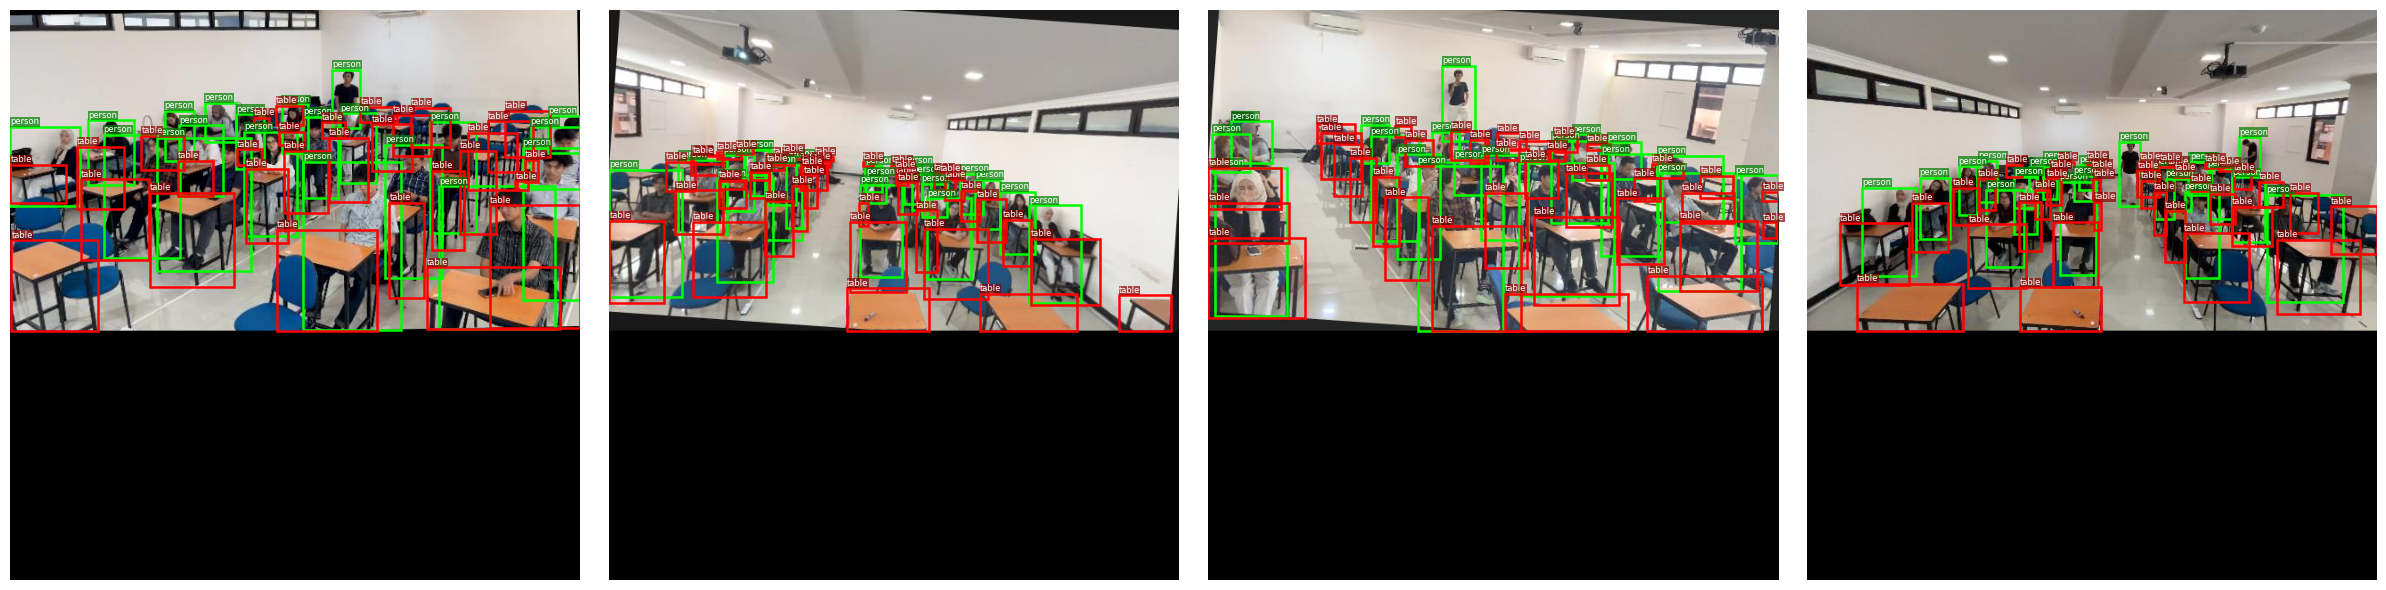

In [ ]:
import random
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def denormalize(image_tensor, mean, std):
    img = image_tensor.permute(1, 2, 0).cpu().numpy()
    img = img * std + mean
    return np.clip(img, 0, 1)


def show_samples(dataset, num_samples=4):
    # Warna tiap kelas
    class_colors = {
        "person": ("lime", "green"),
        "table": ("red", "darkred")
    }

    fig, axes = plt.subplots(1, num_samples, figsize=(6 * num_samples, 6))

    indices = random.sample(range(len(dataset)), num_samples)

    for ax, idx in zip(axes, indices):

        image_tensor, target = dataset[idx]
        img = denormalize(
            image_tensor,
            dataset.imagenet_mean,
            dataset.imagenet_std
        )

        ax.imshow(img)

        for box, label in zip(target["bbox"], target["cls"]):

            # Format bbox EfficientDet
            y1, x1, y2, x2 = box.tolist()

            class_name = dataset.label_to_name[int(label)]

            edge_color, bg_color = class_colors.get(
                class_name,
                ("yellow", "black")
            )

            rect = patches.Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                linewidth=1.8,
                edgecolor=edge_color,
                facecolor="none"
            )
            ax.add_patch(rect)

            ax.text(
                x1,
                max(y1 - 3, 3),
                class_name,
                fontsize=6,
                color="white",
                bbox=dict(
                    facecolor=bg_color,
                    alpha=0.7,
                    edgecolor="none",
                    pad=0.15
                )
            )

        ax.axis("off")

    plt.tight_layout()
    plt.show()


show_samples(train_dataset, num_samples=4)

## Step 4 — Membangun Model EfficientDet-D0



In [ ]:
def build_model(num_classes, image_size, model_name='tf_efficientdet_d0', pretrained=True):
    config = get_efficientdet_config(model_name)
    config.image_size = (image_size, image_size)
    config.num_classes = num_classes

    net = EfficientDet(config, pretrained_backbone=pretrained)
    net.class_net = HeadNet(config, num_outputs=num_classes)
    return net, config


In [ ]:
def build_optimizer_and_scheduler(model, base_lr, num_epochs, warmup_epochs=3,
                                    warmup_start_factor=0.1, weight_decay=1e-5):
    optimizer = torch.optim.AdamW(model.parameters(), lr=base_lr, weight_decay=weight_decay)

    # Fase 1: LR naik linear dari (warmup_start_factor * base_lr) ke base_lr selama warmup_epochs
    warmup_scheduler = LinearLR(optimizer, start_factor=warmup_start_factor,
                                 end_factor=1.0, total_iters=warmup_epochs)

    # Fase 2: LR turun mengikuti kurva kosinus untuk sisa epoch
    cosine_epochs = max(num_epochs - warmup_epochs, 1)
    cosine_scheduler = CosineAnnealingLR(optimizer, T_max=cosine_epochs)

    # Gabungkan kedua fase: pindah dari warmup ke cosine tepat di epoch ke-(warmup_epochs)
    scheduler = SequentialLR(optimizer, schedulers=[warmup_scheduler, cosine_scheduler],
                              milestones=[warmup_epochs])
    return optimizer, scheduler


## Step 6 — Fungsi Training & Validasi per Epoch




In [ ]:
def train_one_epoch(model, loader, optimizer, device):
    model.train()
    running_loss = 0.0
    for images, batch_target, _ in loader:
        images = images.to(device)
        target = {
            'bbox': [b.to(device) for b in batch_target['bbox']],
            'cls': [c.to(device) for c in batch_target['cls']],
            'image_id': batch_target['image_id'].to(device),
            'img_scale': batch_target['img_scale'].to(device),
            'img_size': batch_target['img_size'].to(device),
        }
        optimizer.zero_grad()
        losses = model(images, target)
        loss = losses['loss']
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    return running_loss / len(loader)


@torch.no_grad()
def validate(model, loader, device):
    model.eval()
    running_loss = 0.0
    for images, batch_target, _ in loader:
        images = images.to(device)
        target = {
            'bbox': [b.to(device) for b in batch_target['bbox']],
            'cls': [c.to(device) for c in batch_target['cls']],
            'image_id': batch_target['image_id'].to(device),
            'img_scale': batch_target['img_scale'].to(device),
            'img_size': batch_target['img_size'].to(device),
        }
        losses = model(images, target)
        running_loss += losses['loss'].item()
    return running_loss / len(loader)


## Step 7 — Hyperparameter Tuning: Mencari Kombinasi LR + Batch Size + Weight Decay Terbaik

Berbeda dari versi sebelumnya yang hanya menguji learning rate, tahap ini men-tuning **tiga hyperparameter sekaligus**: learning rate (`LR_CANDIDATES`), batch size (`BATCH_SIZE_CANDIDATES`), dan weight decay (`WEIGHT_DECAY_CANDIDATES`).

In [ ]:
import itertools

all_combinations = list(itertools.product(LR_CANDIDATES, BATCH_SIZE_CANDIDATES, WEIGHT_DECAY_CANDIDATES))
print(f"Total kemungkinan kombinasi (grid penuh): {len(all_combinations)}")

random.seed(42)
n_trials = min(N_SEARCH_TRIALS, len(all_combinations))
search_combinations = random.sample(all_combinations, n_trials)

print(f"Menguji {n_trials} kombinasi (random search) dari {len(all_combinations)} total kemungkinan:")
for combo in search_combinations:
    print(f"  lr={combo[0]}, batch_size={combo[1]}, weight_decay={combo[2]}")

hp_search_results = []

for trial_idx, (cand_lr, cand_batch_size, cand_weight_decay) in enumerate(search_combinations, start=1):
    print(f"\n=== Trial {trial_idx}/{n_trials}: lr={cand_lr}, batch_size={cand_batch_size}, weight_decay={cand_weight_decay} ===")

    trial_train_loader = DataLoader(train_dataset, batch_size=cand_batch_size, shuffle=True,
                                     num_workers=NUM_WORKERS, collate_fn=collate_fn, drop_last=True)
    trial_valid_loader = DataLoader(valid_dataset, batch_size=cand_batch_size, shuffle=False,
                                     num_workers=NUM_WORKERS, collate_fn=collate_fn)

    trial_net, trial_config = build_model(NUM_CLASSES, IMAGE_SIZE, MODEL_NAME, pretrained=True)
    trial_bench = DetBenchTrain(trial_net, trial_config).to(device)
    trial_optimizer, trial_scheduler = build_optimizer_and_scheduler(
        trial_bench, cand_lr, LR_SEARCH_EPOCHS, WARMUP_EPOCHS, WARMUP_START_FACTOR, cand_weight_decay
    )

    best_trial_val_loss = float('inf')
    for epoch in range(1, LR_SEARCH_EPOCHS + 1):
        train_loss = train_one_epoch(trial_bench, trial_train_loader, trial_optimizer, device)
        val_loss = validate(trial_bench, trial_valid_loader, device)
        trial_scheduler.step()
        best_trial_val_loss = min(best_trial_val_loss, val_loss)
        print(f"  epoch {epoch}/{LR_SEARCH_EPOCHS}  train_loss={train_loss:.4f}  val_loss={val_loss:.4f}")

    hp_search_results.append({
        'lr': cand_lr,
        'batch_size': cand_batch_size,
        'weight_decay': cand_weight_decay,
        'best_val_loss': best_trial_val_loss,
    })
    print(f"  -> val_loss terbaik untuk kombinasi ini: {best_trial_val_loss:.4f}")

    # Bersihkan memori GPU sebelum mencoba kombinasi berikutnya
    del trial_net, trial_bench, trial_optimizer, trial_scheduler, trial_train_loader, trial_valid_loader
    torch.cuda.empty_cache()

hp_search_df = pd.DataFrame(hp_search_results).sort_values('best_val_loss').reset_index(drop=True)
print("\nRingkasan hasil hyperparameter tuning (diurutkan dari val_loss terbaik):")
print(hp_search_df)

best_combo = hp_search_df.iloc[0]
BEST_LR = float(best_combo['lr'])
BEST_BATCH_SIZE = int(best_combo['batch_size'])
BEST_WEIGHT_DECAY = float(best_combo['weight_decay'])

print(f"\nKombinasi terbaik: lr={BEST_LR}, batch_size={BEST_BATCH_SIZE}, weight_decay={BEST_WEIGHT_DECAY}")

with open(os.path.join(OUTPUT_DIR, 'hp_search_results.json'), 'w') as f:
    json.dump(hp_search_results, f, indent=2)


Total kemungkinan kombinasi (grid penuh): 27
Menguji 8 kombinasi (random search) dari 27 total kemungkinan:
  lr=0.0003, batch_size=4, weight_decay=0.0001
  lr=5e-05, batch_size=8, weight_decay=0.0
  lr=5e-05, batch_size=4, weight_decay=0.0
  lr=0.0003, batch_size=8, weight_decay=0.0001
  lr=5e-05, batch_size=16, weight_decay=0.0001
  lr=5e-05, batch_size=16, weight_decay=1e-05
  lr=0.0003, batch_size=8, weight_decay=0.0
  lr=5e-05, batch_size=8, weight_decay=1e-05

=== Trial 1/8: lr=0.0003, batch_size=4, weight_decay=0.0001 ===


model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

  epoch 1/5  train_loss=29.0729  val_loss=29.5672
  epoch 2/5  train_loss=18.2920  val_loss=9.2718
  epoch 3/5  train_loss=3.8493  val_loss=1.6784
  epoch 4/5  train_loss=1.2454  val_loss=1.0372
  epoch 5/5  train_loss=0.9363  val_loss=0.8899
  -> val_loss terbaik untuk kombinasi ini: 0.8899

=== Trial 2/8: lr=5e-05, batch_size=8, weight_decay=0.0 ===


  epoch 1/5  train_loss=31.3660  val_loss=29.8231
  epoch 2/5  train_loss=29.3465  val_loss=29.8355
  epoch 3/5  train_loss=27.7137  val_loss=29.3143
  epoch 4/5  train_loss=25.7417  val_loss=24.3997
  epoch 5/5  train_loss=23.3143  val_loss=22.3705
  -> val_loss terbaik untuk kombinasi ini: 22.3705

=== Trial 3/8: lr=5e-05, batch_size=4, weight_decay=0.0 ===


  epoch 1/5  train_loss=30.5619  val_loss=29.7567
  epoch 2/5  train_loss=27.9955  val_loss=28.4737
  epoch 3/5  train_loss=24.3811  val_loss=19.6086
  epoch 4/5  train_loss=17.7960  val_loss=12.7658
  epoch 5/5  train_loss=12.3387  val_loss=11.0783
  -> val_loss terbaik untuk kombinasi ini: 11.0783

=== Trial 4/8: lr=0.0003, batch_size=8, weight_decay=0.0001 ===


  epoch 1/5  train_loss=29.7918  val_loss=29.8508
  epoch 2/5  train_loss=24.9004  val_loss=26.4127
  epoch 3/5  train_loss=12.2945  val_loss=5.3565
  epoch 4/5  train_loss=2.8844  val_loss=1.5181
  epoch 5/5  train_loss=1.4659  val_loss=1.3017
  -> val_loss terbaik untuk kombinasi ini: 1.3017

=== Trial 5/8: lr=5e-05, batch_size=16, weight_decay=0.0001 ===


  epoch 1/5  train_loss=32.5527  val_loss=31.0187
  epoch 2/5  train_loss=31.1889  val_loss=30.9847
  epoch 3/5  train_loss=29.7236  val_loss=30.8748
  epoch 4/5  train_loss=28.5238  val_loss=30.6443
  epoch 5/5  train_loss=27.5525  val_loss=30.2074
  -> val_loss terbaik untuk kombinasi ini: 30.2074

=== Trial 6/8: lr=5e-05, batch_size=16, weight_decay=1e-05 ===


  epoch 1/5  train_loss=30.6056  val_loss=29.1733
  epoch 2/5  train_loss=29.2432  val_loss=29.1746
  epoch 3/5  train_loss=27.7174  val_loss=29.0533
  epoch 4/5  train_loss=26.6397  val_loss=28.7219
  epoch 5/5  train_loss=25.8161  val_loss=28.3180
  -> val_loss terbaik untuk kombinasi ini: 28.3180

=== Trial 7/8: lr=0.0003, batch_size=8, weight_decay=0.0 ===


  epoch 1/5  train_loss=29.9894  val_loss=30.7590
  epoch 2/5  train_loss=24.7640  val_loss=27.2129
  epoch 3/5  train_loss=12.2620  val_loss=5.0037
  epoch 4/5  train_loss=2.9685  val_loss=1.5958
  epoch 5/5  train_loss=1.5023  val_loss=1.3454
  -> val_loss terbaik untuk kombinasi ini: 1.3454

=== Trial 8/8: lr=5e-05, batch_size=8, weight_decay=1e-05 ===


  epoch 1/5  train_loss=30.5621  val_loss=29.2031
  epoch 2/5  train_loss=28.2651  val_loss=29.0324
  epoch 3/5  train_loss=25.7819  val_loss=26.8819
  epoch 4/5  train_loss=22.7181  val_loss=19.0333
  epoch 5/5  train_loss=19.9601  val_loss=18.3730
  -> val_loss terbaik untuk kombinasi ini: 18.3730

Ringkasan hasil hyperparameter tuning (diurutkan dari val_loss terbaik):
        lr  batch_size  weight_decay  best_val_loss
0  0.00030           4       0.00010       0.889874
1  0.00030           8       0.00010       1.301651
2  0.00030           8       0.00000       1.345353
3  0.00005           4       0.00000      11.078317
4  0.00005           8       0.00001      18.373047
5  0.00005           8       0.00000      22.370459
6  0.00005          16       0.00001      28.317951
7  0.00005          16       0.00010      30.207408

Kombinasi terbaik: lr=0.0003, batch_size=4, weight_decay=0.0001


## Step 8 — Inisialisasi Model Final dengan Kombinasi Hyperparameter Terbaik


In [ ]:
train_loader = DataLoader(train_dataset, batch_size=BEST_BATCH_SIZE, shuffle=True,
                           num_workers=NUM_WORKERS, collate_fn=collate_fn, drop_last=True)
valid_loader = DataLoader(valid_dataset, batch_size=BEST_BATCH_SIZE, shuffle=False,
                           num_workers=NUM_WORKERS, collate_fn=collate_fn)

net, model_config = build_model(NUM_CLASSES, IMAGE_SIZE, MODEL_NAME, pretrained=True)
train_bench = DetBenchTrain(net, model_config).to(device)

optimizer, scheduler = build_optimizer_and_scheduler(
    train_bench, BEST_LR, NUM_EPOCHS, WARMUP_EPOCHS, WARMUP_START_FACTOR, BEST_WEIGHT_DECAY
)

total_params = sum(p.numel() for p in net.parameters())
trainable_params = sum(p.numel() for p in net.parameters() if p.requires_grad)
print(f"Model final dibangun ulang dari awal (bobot pretrained segar) dengan:")
print(f"  learning rate  = {BEST_LR}")
print(f"  batch size     = {BEST_BATCH_SIZE}")
print(f"  weight decay   = {BEST_WEIGHT_DECAY}")
print(f"Total parameter model : {total_params:,}")
print(f"Parameter trainable   : {trainable_params:,}")


Model final dibangun ulang dari awal (bobot pretrained segar) dengan:
  learning rate  = 0.0003
  batch size     = 4
  weight decay   = 0.0001
Total parameter model : 3,828,587
Parameter trainable   : 3,828,587


## Step 9 — Main Training Loop




In [ ]:
# ============================================================
# TRAINING EFFICIENTDET-D0 DENGAN EARLY STOPPING
# ============================================================

# Riwayat training
history = {
    'train_loss': [],
    'val_loss': []
}

# Nilai validation loss terbaik
best_val_loss = float('inf')

# Path penyimpanan model terbaik
best_ckpt_path = os.path.join(
    OUTPUT_DIR,
    'efficientdet_d0_best.pth'
)

# ============================================================
# KONFIGURASI EARLY STOPPING
# ============================================================

# Minimum perubahan val_loss yang dianggap improvement
MIN_DELTA = 0.0001

# Counter epoch tanpa improvement
epochs_without_improvement = 0

# Menyimpan epoch terbaik
best_epoch = 0

# Status early stopping
early_stopped = True


# ============================================================
# MULAI PENGUKURAN WAKTU TRAINING
# ============================================================

start_time = time.time()


# ============================================================
# TRAINING LOOP
# ============================================================

for epoch in range(1, NUM_EPOCHS + 1):

    epoch_start = time.time()


    # ========================================================
    # TRAINING SATU EPOCH
    # ========================================================

    train_loss = train_one_epoch(
        train_bench,
        train_loader,
        optimizer,
        device
    )


    # ========================================================
    # VALIDATION
    # ========================================================

    val_loss = validate(
        train_bench,
        valid_loader,
        device
    )


    # ========================================================
    # UPDATE LEARNING RATE SCHEDULER
    # ========================================================

    scheduler.step()


    # ========================================================
    # SIMPAN TRAINING HISTORY
    # ========================================================

    history['train_loss'].append(
        train_loss
    )

    history['val_loss'].append(
        val_loss
    )


    # ========================================================
    # INFORMASI TRAINING
    # ========================================================

    epoch_time = time.time() - epoch_start

    current_lr = scheduler.get_last_lr()[0]


    print(
        f"Epoch [{epoch}/{NUM_EPOCHS}] "
        f"train_loss={train_loss:.4f}  "
        f"val_loss={val_loss:.4f}  "
        f"lr={current_lr:.6f}  "
        f"waktu={epoch_time:.1f}s"
    )


    # ========================================================
    # CEK APAKAH VALIDATION LOSS MEMBAIK
    # ========================================================

    if val_loss < (best_val_loss - MIN_DELTA):

        # Update validation loss terbaik
        best_val_loss = val_loss

        # Simpan epoch terbaik
        best_epoch = epoch

        # Reset counter Early Stopping
        epochs_without_improvement = 0


        # ====================================================
        # SIMPAN MODEL TERBAIK
        # ====================================================

        torch.save(
            net.state_dict(),
            best_ckpt_path
        )


        print(
            f"  -> Model terbaik disimpan "
            f"(val_loss={val_loss:.4f}) "
            f"pada epoch {epoch}"
        )


    else:

        # Tambahkan counter jika tidak ada improvement
        epochs_without_improvement += 1


        print(
            f"  -> Tidak ada improvement | "
            f"EarlyStopping: "
            f"{epochs_without_improvement}/{PATIENCE}"
        )


    # ========================================================
    # CEK EARLY STOPPING
    # ========================================================

    if epochs_without_improvement >= PATIENCE:

        early_stopped = True


        print(
            "\n============================================"
        )

        print(
            "EARLY STOPPING"
        )

        print(
            "============================================"
        )

        print(
            f"Tidak ada perbaikan validation loss "
            f"selama {PATIENCE} epoch berturut-turut."
        )

        print(
            f"Training dihentikan pada epoch {epoch}."
        )

        print(
            f"Model terbaik ditemukan pada epoch "
            f"{best_epoch}."
        )

        print(
            f"Best validation loss: "
            f"{best_val_loss:.4f}"
        )

        print(
            "============================================"
        )


        # Hentikan training loop
        break


# ============================================================
# SELESAI TRAINING
# ============================================================

total_time = time.time() - start_time

epochs_completed = len(
    history['train_loss']
)


# ============================================================
# RINGKASAN TRAINING
# ============================================================

print(
    "\n============================================"
)

print(
    "RINGKASAN TRAINING EFFICIENTDET-D0"
)

print(
    "============================================"
)

print(
    f"Total waktu training     : "
    f"{total_time/60:.1f} menit"
)

print(
    f"Epoch dijalankan         : "
    f"{epochs_completed}/{NUM_EPOCHS}"
)

print(
    f"Epoch terbaik            : "
    f"{best_epoch}"
)

print(
    f"Best validation loss     : "
    f"{best_val_loss:.4f}"
)

print(
    f"Early Stopping Patience  : "
    f"{PATIENCE}"
)


if early_stopped:

    print(
        "Status                   : "
        "Training dihentikan oleh Early Stopping"
    )

else:

    print(
        "Status                   : "
        "Training mencapai maksimum epoch"
    )


print(
    "============================================"
)


# ============================================================
# SIMPAN TRAINING HISTORY
# ============================================================

history_path = os.path.join(
    OUTPUT_DIR,
    'training_history.json'
)


with open(
    history_path,
    'w'
) as f:

    json.dump(
        history,
        f,
        indent=2
    )


print(
    f"\nTraining history disimpan di:\n"
    f"{history_path}"
)

print(
    f"\nModel terbaik disimpan di:\n"
    f"{best_ckpt_path}"
)


Epoch [1/100] train_loss=30.4051  val_loss=30.2949  lr=0.000120  waktu=39.9s
  -> Model terbaik disimpan (val_loss=30.2949) pada epoch 1
Epoch [2/100] train_loss=19.7631  val_loss=9.3884  lr=0.000210  waktu=40.0s
  -> Model terbaik disimpan (val_loss=9.3884) pada epoch 2
Epoch [3/100] train_loss=3.8650  val_loss=1.5810  lr=0.000300  waktu=40.5s
  -> Model terbaik disimpan (val_loss=1.5810) pada epoch 3
Epoch [4/100] train_loss=1.2271  val_loss=0.9977  lr=0.000300  waktu=39.9s
  -> Model terbaik disimpan (val_loss=0.9977) pada epoch 4
Epoch [5/100] train_loss=0.8788  val_loss=0.8067  lr=0.000300  waktu=40.0s
  -> Model terbaik disimpan (val_loss=0.8067) pada epoch 5
Epoch [6/100] train_loss=0.7073  val_loss=0.6573  lr=0.000299  waktu=39.9s
  -> Model terbaik disimpan (val_loss=0.6573) pada epoch 6
Epoch [7/100] train_loss=0.6028  val_loss=0.5733  lr=0.000299  waktu=40.0s
  -> Model terbaik disimpan (val_loss=0.5733) pada epoch 7
Epoch [8/100] train_loss=0.5339  val_loss=0.5066  lr=0.000

## Step 10 — Plot Kurva Training & Validation Loss


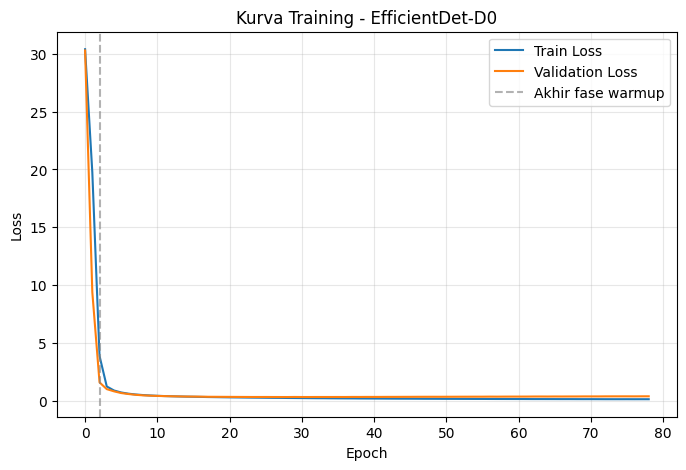

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(history['train_loss'], label='Train Loss')
plt.plot(history['val_loss'], label='Validation Loss')
plt.axvline(x=WARMUP_EPOCHS - 1, color='gray', linestyle='--', alpha=0.6, label='Akhir fase warmup')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Kurva Training - EfficientDet-D0')
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(os.path.join(OUTPUT_DIR, 'loss_curve.png'), dpi=150, bbox_inches='tight')
plt.show()


## Step 11 — Evaluasi mAP@50 dan mAP@50-95 pada Test Set



In [ ]:
# ==========================================================
# LOAD MODEL TERBAIK
# ==========================================================
net.load_state_dict(torch.load(best_ckpt_path, map_location=device))

predict_bench = DetBenchPredict(net).to(device)
predict_bench.eval()

# Threshold rendah agar seluruh prediksi digunakan saat evaluasi COCO
MAP_EVAL_THRESHOLD = 0.001

coco_results = []

# ==========================================================
# INFERENCE PADA TEST SET
# ==========================================================
with torch.no_grad():

    for images, batch_target, targets in test_loader:

        images = images.to(device)

        img_size_tensor = batch_target['img_size'].to(device)
        img_scale_tensor = batch_target['img_scale'].to(device)

        detections = predict_bench(
            images,
            {
                'img_size': img_size_tensor,
                'img_scale': img_scale_tensor
            }
        )

        det = detections[0].cpu().numpy()

        image_id = int(targets[0]['image_id'].item())

        for x1, y1, x2, y2, score, label_effdet in det:

            if score < MAP_EVAL_THRESHOLD:
                continue

            w = x2 - x1
            h = y2 - y1

            coco_results.append({
                "image_id": image_id,
                "category_id": test_dataset.label_to_cat_id[int(label_effdet)],
                "bbox": [
                    float(x1),
                    float(y1),
                    float(w),
                    float(h)
                ],
                "score": float(score)
            })

# ==========================================================
# SIMPAN HASIL PREDIKSI
# ==========================================================
results_path = os.path.join(
    OUTPUT_DIR,
    "test_predictions_coco.json"
)

with open(results_path, "w") as f:
    json.dump(coco_results, f)

# ==========================================================
# EVALUASI COCO
# ==========================================================
coco_gt = test_dataset.coco
coco_dt = coco_gt.loadRes(results_path)

coco_eval = COCOeval(
    coco_gt,
    coco_dt,
    iouType="bbox"
)

coco_eval.evaluate()
coco_eval.accumulate()
coco_eval.summarize()

# ==========================================================
# AMBIL METRIK mAP
# ==========================================================
mAP_50_95 = coco_eval.stats[0]   # AP@[0.50:0.95]
mAP_50 = coco_eval.stats[1]      # AP@0.50

# ==========================================================
# HITUNG MEAN PRECISION DAN MEAN RECALL
# ==========================================================
precision = coco_eval.eval["precision"]
recall = coco_eval.eval["recall"]

valid_precision = precision[precision > -1]
valid_recall = recall[recall > -1]

mean_precision = (
    valid_precision.mean()
    if len(valid_precision) > 0
    else 0.0
)

mean_recall = (
    valid_recall.mean()
    if len(valid_recall) > 0
    else 0.0
)

# ==========================================================
# HASIL EVALUASI
# ==========================================================
print("\n" + "=" * 50)
print("           HASIL EVALUASI TEST SET")
print("=" * 50)

print(f"Precision (mP) : {mean_precision:.4f}")
print(f"Recall (mR)    : {mean_recall:.4f}")
print(f"mAP@50         : {mAP_50:.4f}")
print(f"mAP@50-95      : {mAP_50_95:.4f}")

print("=" * 50)

Loading and preparing results...
DONE (t=0.02s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=1.99s).
Accumulating evaluation results...
DONE (t=0.05s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.376
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.684
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.364
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.207
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.460
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.577
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.026
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.230
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.447
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=10

## Step 12 — Confusion Matrix



Confusion Matrix (baris = ground truth, kolom = prediksi):
            person  table  background
person         788      7         232
table           26    936         644
background     472    378           0


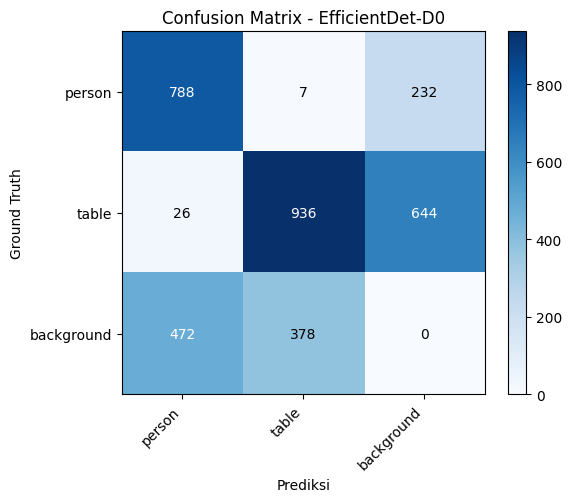

In [ ]:
def compute_iou(box1, box2):
    # format box: [x1, y1, x2, y2]
    xx1 = max(box1[0], box2[0])
    yy1 = max(box1[1], box2[1])
    xx2 = min(box1[2], box2[2])
    yy2 = min(box1[3], box2[3])

    inter_w = max(0.0, xx2 - xx1)
    inter_h = max(0.0, yy2 - yy1)
    inter_area = inter_w * inter_h

    area1 = max(0.0, box1[2] - box1[0]) * max(0.0, box1[3] - box1[1])
    area2 = max(0.0, box2[2] - box2[0]) * max(0.0, box2[3] - box2[1])
    union_area = area1 + area2 - inter_area
    if union_area <= 0:
        return 0.0
    return inter_area / union_area


class_names_ordered = [test_dataset.label_to_name[i + 1] for i in range(NUM_CLASSES)]
all_names = class_names_ordered + ['background']
n_labels = len(all_names)
BACKGROUND_IDX = n_labels - 1

confusion_matrix = np.zeros((n_labels, n_labels), dtype=int)

predict_bench.eval()
with torch.no_grad():
    for images, batch_target, targets in test_loader:
        images = images.to(device)
        img_size = batch_target['img_size'].to(device)
        img_scale = batch_target['img_scale'].to(device)
        detections = predict_bench(images, {'img_size': img_size, 'img_scale': img_scale})

        det = detections[0].cpu().numpy()
        det = det[det[:, 4] >= CONF_THRESHOLD]
        det = det[det[:, 4].argsort()[::-1]]  # urutkan dari confidence tertinggi

        gt_boxes = targets[0]['bbox'].numpy()   # format [y1, x1, y2, x2]
        gt_labels = targets[0]['cls'].numpy()
        matched_gt = np.zeros(len(gt_boxes), dtype=bool)

        for x1, y1, x2, y2, score, pred_label in det:
            pred_idx = int(pred_label) - 1
            best_iou, best_gi = 0.0, -1
            for gi, gt_box in enumerate(gt_boxes):
                if matched_gt[gi]:
                    continue
                gy1, gx1, gy2, gx2 = gt_box
                iou = compute_iou([x1, y1, x2, y2], [gx1, gy1, gx2, gy2])
                if iou > best_iou:
                    best_iou, best_gi = iou, gi

            if best_iou >= IOU_THRESHOLD:
                matched_gt[best_gi] = True
                gt_idx = int(gt_labels[best_gi]) - 1
                confusion_matrix[gt_idx, pred_idx] += 1
            else:
                confusion_matrix[BACKGROUND_IDX, pred_idx] += 1

        for gi, matched in enumerate(matched_gt):
            if not matched:
                gt_idx = int(gt_labels[gi]) - 1
                confusion_matrix[gt_idx, BACKGROUND_IDX] += 1

cm_df = pd.DataFrame(confusion_matrix, index=all_names, columns=all_names)
print("Confusion Matrix (baris = ground truth, kolom = prediksi):")
print(cm_df)

# Visualisasi heatmap
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(confusion_matrix, cmap='Blues')
ax.set_xticks(range(n_labels))
ax.set_xticklabels(all_names, rotation=45, ha='right')
ax.set_yticks(range(n_labels))
ax.set_yticklabels(all_names)
ax.set_xlabel('Prediksi')
ax.set_ylabel('Ground Truth')
ax.set_title('Confusion Matrix - EfficientDet-D0')
for i in range(n_labels):
    for j in range(n_labels):
        color = 'white' if confusion_matrix[i, j] > confusion_matrix.max() / 2 else 'black'
        ax.text(j, i, confusion_matrix[i, j], ha='center', va='center', color=color)
plt.colorbar(im)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'confusion_matrix.png'), dpi=150, bbox_inches='tight')
plt.show()

cm_df.to_csv(os.path.join(OUTPUT_DIR, 'confusion_matrix.csv'))


## Step 13 — Mengukur FPS (Kecepatan Inferensi)



In [ ]:
def measure_fps(predict_bench, dataset, device, num_warmup=10, num_iterations=100):
    predict_bench.eval()

    # Ambil satu sample (batch size = 1) untuk dipakai berulang selama pengukuran
    image_tensor, target = dataset[0]
    images = image_tensor.unsqueeze(0).to(device)
    img_info = {
        'img_size': target['img_size'].to(device),
        'img_scale': target['img_scale'].to(device),
    }

    # Warm-up: forward pass awal tidak dihitung karena GPU/CUDA masih 'dingin'
    with torch.no_grad():
        for _ in range(num_warmup):
            _ = predict_bench(images, img_info)
            if device.type == 'cuda':
                torch.cuda.synchronize()

    # Pengukuran waktu inferensi murni
    timings = []
    with torch.no_grad():
        for _ in range(num_iterations):
            if device.type == 'cuda':
                torch.cuda.synchronize()
            start = time.time()

            _ = predict_bench(images, img_info)

            if device.type == 'cuda':
                torch.cuda.synchronize()
            end = time.time()
            timings.append(end - start)

    avg_time_sec = np.mean(timings)
    std_time_sec = np.std(timings)
    fps = 1.0 / avg_time_sec

    print(f"Rata-rata waktu inferensi : {avg_time_sec * 1000:.2f} ms (+/- {std_time_sec * 1000:.2f} ms)")
    print(f"FPS (batch size = 1)      : {fps:.2f} frame/detik")
    print(f"Device                    : {device} ({torch.cuda.get_device_name(0) if device.type == 'cuda' else 'CPU'})")

    return {
        'avg_inference_time_ms': float(avg_time_sec * 1000),
        'std_inference_time_ms': float(std_time_sec * 1000),
        'fps': float(fps),
        'device': str(device),
        'device_name': torch.cuda.get_device_name(0) if device.type == 'cuda' else 'CPU',
    }


fps_results = measure_fps(predict_bench, test_dataset, device, num_warmup=10, num_iterations=100)

# Simpan hasil FPS ke Drive agar bisa langsung dipakai untuk tabel perbandingan dengan YOLOv8
with open(os.path.join(OUTPUT_DIR, 'fps_results.json'), 'w') as f:
    json.dump(fps_results, f, indent=2)


Rata-rata waktu inferensi : 30.18 ms (+/- 0.55 ms)
FPS (batch size = 1)      : 33.14 frame/detik
Device                    : cuda (NVIDIA A100-SXM4-80GB)


## Step 14 — Evaluasi Object Counting: MAE (tanpa RMSE)



In [ ]:
def count_objects_per_class(cls_array, label_to_name):
    counts = {name: 0 for name in label_to_name.values()}
    for c in cls_array:
        name = label_to_name.get(int(c))
        if name is not None:
            counts[name] += 1
    return counts


gt_counts_list = []
pred_counts_list = []

predict_bench.eval()
with torch.no_grad():
    for images, batch_target, targets in test_loader:
        images = images.to(device)
        img_size_tensor = batch_target['img_size'].to(device)
        img_scale_tensor = batch_target['img_scale'].to(device)

        detections = predict_bench(images, {'img_size': img_size_tensor, 'img_scale': img_scale_tensor})
        det = detections[0].cpu().numpy()
        pred_classes = det[det[:, 4] >= CONF_THRESHOLD][:, 5]

        gt_classes = targets[0]['cls'].numpy()

        gt_counts_list.append(count_objects_per_class(gt_classes, test_dataset.label_to_name))
        pred_counts_list.append(count_objects_per_class(pred_classes, test_dataset.label_to_name))

gt_df = pd.DataFrame(gt_counts_list)
pred_df = pd.DataFrame(pred_counts_list)

counting_metrics = {}
for class_name in gt_df.columns:
    diff = gt_df[class_name] - pred_df[class_name]
    mae = diff.abs().mean()
    counting_metrics[class_name] = {'MAE': float(mae)}
    print(f"Kelas '{class_name}': MAE = {mae:.3f}")

all_diffs = pd.concat([gt_df[c] - pred_df[c] for c in gt_df.columns])
overall_mae = all_diffs.abs().mean()
print(f"\nMAE keseluruhan (semua kelas): {overall_mae:.3f}")
counting_metrics['overall'] = {'MAE': float(overall_mae)}

with open(os.path.join(OUTPUT_DIR, 'counting_metrics.json'), 'w') as f:
    json.dump(counting_metrics, f, indent=2)


Kelas 'person': MAE = 5.820
Kelas 'table': MAE = 6.060

MAE keseluruhan (semua kelas): 5.940


## Step 15 — GFLOPs & Jumlah Parameter Model


In [ ]:
dummy_input = torch.randn(1, 3, IMAGE_SIZE, IMAGE_SIZE).to(device)
net.eval()
with torch.no_grad():
    macs, params = profile(net, inputs=(dummy_input,), verbose=False)

gflops = (2 * macs) / 1e9
params_million = params / 1e6

print(f"GFLOPs            : {gflops:.2f} GFLOPs")
print(f"Jumlah Parameter   : {int(params):,} ({params_million:.2f} juta)")

with open(os.path.join(OUTPUT_DIR, 'model_complexity.json'), 'w') as f:
    json.dump({'gflops': float(gflops), 'num_parameters': int(params)}, f, indent=2)


GFLOPs            : 6.68 GFLOPs
Jumlah Parameter   : 3,764,786 (3.76 juta)


## Step 16 — Simulasi Counting & Visualisasi Hasil



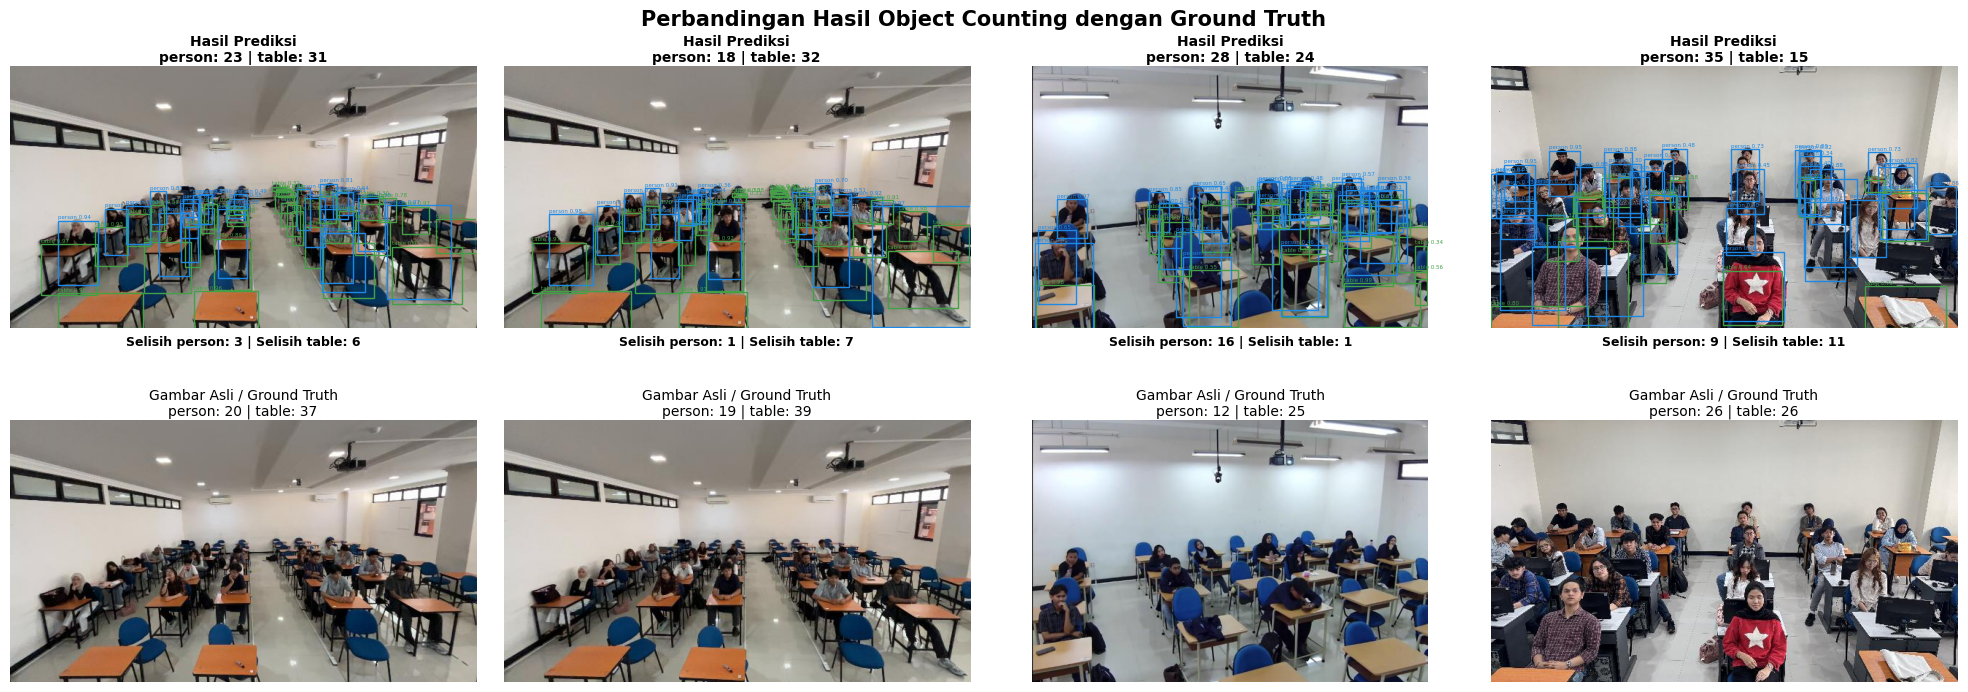


RINGKASAN SIMULASI OBJECT COUNTING
person  : Ground Truth =  77 | Prediksi = 104 | Selisih = 27
table   : Ground Truth = 127 | Prediksi = 102 | Selisih = 25
Hasil visualisasi disimpan di: /content/drive/MyDrive/Classroom Dataset/Ruang Kelas/efficientdet_d0_outputsv2/counting_simulation.png


In [ ]:
import os
import random
import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as patches


# ============================================================
# FUNGSI MENGHILANGKAN PADDING HITAM
# ============================================================
def remove_black_padding(img, threshold=5):
    """
    Menghapus padding hitam pada bagian gambar untuk visualisasi.
    Tidak memengaruhi proses prediksi model.
    """

    img_np = np.asarray(img)

    # Sesuaikan threshold jika gambar memiliki rentang nilai 0-1
    current_threshold = threshold

    if img_np.max() <= 1.0:
        current_threshold = threshold / 255.0

    # Cari baris yang memiliki pixel non-hitam
    if img_np.ndim == 3:
        valid_rows = np.any(
            img_np > current_threshold,
            axis=(1, 2)
        )
    else:
        valid_rows = np.any(
            img_np > current_threshold,
            axis=1
        )

    # Crop padding hitam
    if np.any(valid_rows):

        valid_indices = np.where(valid_rows)[0]

        first_valid_row = valid_indices[0]
        last_valid_row = valid_indices[-1]

        img_np = img_np[
            first_valid_row:last_valid_row + 1,
            :
        ]

    return img_np


# ============================================================
# FUNGSI SIMULASI OBJECT COUNTING
# ============================================================
def simulate_counting(
    dataset,
    predict_bench,
    device,
    num_samples=4,
    conf_threshold=0.3
):

    # ========================================================
    # PILIH GAMBAR TEST SECARA ACAK
    # ========================================================
    actual_samples = min(
        num_samples,
        len(dataset)
    )

    indices = random.sample(
        range(len(dataset)),
        actual_samples
    )


    # ========================================================
    # SIAPKAN FIGURE
    #
    # BARIS ATAS  = HASIL PREDIKSI
    # TENGAH      = SELISIH COUNTING
    # BARIS BAWAH = GAMBAR ASLI / GROUND TRUTH
    # ========================================================
    fig, axes = plt.subplots(
        2,
        num_samples,
        figsize=(20, 7)
    )

    # Jika hanya satu gambar
    if num_samples == 1:
        axes = np.array(axes).reshape(2, 1)


    # ========================================================
    # ATUR JARAK FIGURE
    # ========================================================
    plt.subplots_adjust(
        left=0.01,
        right=0.99,
        top=0.90,
        bottom=0.02,
        wspace=0.03,
        hspace=0.35
    )


    # ========================================================
    # WARNA SETIAP KELAS
    # ========================================================
    COLORS = {
        "person": "#1E88E5",
        "table": "#43A047"
    }


    # ========================================================
    # TOTAL COUNTING
    # ========================================================
    all_gt = {
        name: 0
        for name in dataset.label_to_name.values()
    }

    all_pred = {
        name: 0
        for name in dataset.label_to_name.values()
    }


    # ========================================================
    # SIMPAN INFORMASI SELISIH
    # Nanti ditampilkan setelah semua subplot selesai dibuat
    # agar posisinya benar-benar sejajar
    # ========================================================
    diff_texts = []


    # ========================================================
    # MODE EVALUASI
    # ========================================================
    predict_bench.eval()


    # ========================================================
    # PROSES SETIAP GAMBAR
    # ========================================================
    with torch.no_grad():

        for i, idx in enumerate(indices):

            # =================================================
            # AMBIL GAMBAR DAN TARGET
            # =================================================
            image_tensor, target = dataset[idx]

            img_size = target[
                'img_size'
            ].to(device)

            img_scale = target[
                'img_scale'
            ].to(device)

            images = image_tensor.unsqueeze(
                0
            ).to(device)


            # =================================================
            # PREDIKSI EFFICIENTDET
            # =================================================
            detections = predict_bench(
                images,
                {
                    'img_size': img_size,
                    'img_scale': img_scale
                }
            )


            # =================================================
            # AMBIL HASIL DETEKSI
            # =================================================
            det = detections[
                0
            ].cpu().numpy()


            # =================================================
            # FILTER CONFIDENCE THRESHOLD
            # =================================================
            det = det[
                det[:, 4] >= conf_threshold
            ]


            # =================================================
            # DENORMALISASI GAMBAR
            # =================================================
            img_full = denormalize(
                image_tensor,
                dataset.imagenet_mean,
                dataset.imagenet_std
            )


            # =================================================
            # HILANGKAN PADDING HITAM
            # HANYA UNTUK VISUALISASI
            # =================================================
            img = remove_black_padding(
                img_full
            )


            # =================================================
            # HITUNG JUMLAH PREDIKSI
            # =================================================
            pred_counts = {
                name: 0
                for name in dataset.label_to_name.values()
            }


            # =================================================
            # BARIS ATAS
            # TAMPILKAN HASIL PREDIKSI
            # =================================================
            axes[0, i].imshow(
                img
            )


            # =================================================
            # GAMBAR BOUNDING BOX DAN LABEL
            # =================================================
            for (
                x1,
                y1,
                x2,
                y2,
                score,
                label_effdet
            ) in det:

                # =============================================
                # AMBIL NAMA KELAS
                # =============================================
                class_name = dataset.label_to_name.get(
                    int(label_effdet),
                    "unknown"
                )


                # Abaikan kelas tidak dikenal
                if class_name == "unknown":
                    continue


                # =============================================
                # TAMBAHKAN COUNTING
                # =============================================
                pred_counts[
                    class_name
                ] += 1


                # =============================================
                # WARNA KELAS
                # =============================================
                color = COLORS.get(
                    class_name,
                    "yellow"
                )


                # =============================================
                # BOUNDING BOX TIPIS
                # =============================================
                rect = patches.Rectangle(
                    (x1, y1),
                    x2 - x1,
                    y2 - y1,
                    linewidth=1.0,
                    edgecolor=color,
                    facecolor='none'
                )

                axes[
                    0,
                    i
                ].add_patch(
                    rect
                )


                # =============================================
                # LABEL KECIL TANPA BACKGROUND
                # =============================================
                axes[
                    0,
                    i
                ].text(
                    x1,
                    max(
                        3,
                        y1 - 2
                    ),
                    f"{class_name} {score:.2f}",
                    fontsize=4,
                    color=color,
                    weight='normal'
                )


            # =================================================
            # HITUNG GROUND TRUTH
            # =================================================
            gt_counts = count_objects_per_class(
                target[
                    'cls'
                ].cpu().numpy(),
                dataset.label_to_name
            )


            # =================================================
            # AKUMULASI TOTAL COUNTING
            # =================================================
            for name in dataset.label_to_name.values():

                all_gt[
                    name
                ] += gt_counts.get(
                    name,
                    0
                )

                all_pred[
                    name
                ] += pred_counts.get(
                    name,
                    0
                )


            # =================================================
            # HITUNG SELISIH PER GAMBAR
            # =================================================
            differences = {
                name: abs(
                    gt_counts.get(
                        name,
                        0
                    )
                    -
                    pred_counts.get(
                        name,
                        0
                    )
                )
                for name in dataset.label_to_name.values()
            }


            # =================================================
            # SIMPAN TEKS SELISIH
            # =================================================
            diff_text = " | ".join(
                [
                    f"Selisih {name}: {differences[name]}"
                    for name in dataset.label_to_name.values()
                ]
            )

            diff_texts.append(
                diff_text
            )


            # =================================================
            # INFORMASI COUNTING PREDIKSI
            # =================================================
            pred_text = " | ".join(
                [
                    f"{name}: {pred_counts.get(name, 0)}"
                    for name in dataset.label_to_name.values()
                ]
            )


            # =================================================
            # JUDUL GAMBAR PREDIKSI
            # =================================================
            axes[
                0,
                i
            ].set_title(
                f"Hasil Prediksi\n"
                f"{pred_text}",
                fontsize=10,
                fontweight='bold',
                pad=3
            )

            axes[
                0,
                i
            ].axis(
                'off'
            )


            # =================================================
            # BARIS BAWAH
            # GAMBAR ASLI TANPA BOUNDING BOX
            # =================================================
            axes[
                1,
                i
            ].imshow(
                img
            )


            # =================================================
            # INFORMASI GROUND TRUTH
            # =================================================
            gt_text = " | ".join(
                [
                    f"{name}: {gt_counts.get(name, 0)}"
                    for name in dataset.label_to_name.values()
                ]
            )


            # =================================================
            # JUDUL GAMBAR ASLI / GROUND TRUTH
            # =================================================
            axes[
                1,
                i
            ].set_title(
                f"Gambar Asli / Ground Truth\n"
                f"{gt_text}",
                fontsize=10,
                pad=3
            )

            axes[
                1,
                i
            ].axis(
                'off'
            )


    # ========================================================
    # MATIKAN AXIS JIKA GAMBAR KURANG DARI JUMLAH KOLOM
    # ========================================================
    for i in range(
        actual_samples,
        num_samples
    ):

        axes[
            0,
            i
        ].axis(
            'off'
        )

        axes[
            1,
            i
        ].axis(
            'off'
        )


    # ========================================================
    # PAKSA MATPLOTLIB MENYELESAIKAN POSISI SUBPLOT
    # ========================================================
    fig.canvas.draw()


    # ========================================================
    # POSISI VERTIKAL SELISIH
    #
    # SATU NILAI Y DIGUNAKAN UNTUK SEMUA KOLOM
    # SEHINGGA SEMUA TEKS SELISIH LURUS HORIZONTAL
    # ========================================================
    DIFF_Y_POSITION = 0.505


    # ========================================================
    # TAMPILKAN SELISIH
    # ========================================================
    for i in range(actual_samples):

        # Ambil posisi subplot atas
        top_pos = axes[
            0,
            i
        ].get_position()


        # Posisi horizontal tengah masing-masing kolom
        center_x = (
            top_pos.x0
            +
            top_pos.x1
        ) / 2


        # Tampilkan teks selisih
        # Posisi Y sama untuk semua gambar
        fig.text(
            center_x,
            DIFF_Y_POSITION,
            diff_texts[i],
            ha='center',
            va='center',
            fontsize=9,
            fontweight='bold'
        )


    # ========================================================
    # JUDUL UTAMA
    # ========================================================
    fig.suptitle(
        "Perbandingan Hasil Object Counting dengan Ground Truth",
        fontsize=15,
        fontweight='bold',
        y=0.98
    )


    # ========================================================
    # SIMPAN HASIL VISUALISASI
    # ========================================================
    save_path = os.path.join(
        OUTPUT_DIR,
        "counting_simulation.png"
    )


    plt.savefig(
        save_path,
        dpi=200,
        bbox_inches='tight',
        pad_inches=0.05
    )


    # ========================================================
    # TAMPILKAN HASIL
    # ========================================================
    plt.show()


    # ========================================================
    # RINGKASAN SIMULASI OBJECT COUNTING
    # ========================================================
    print(
        "\n========================================"
    )

    print(
        "RINGKASAN SIMULASI OBJECT COUNTING"
    )

    print(
        "========================================"
    )


    for name in dataset.label_to_name.values():

        diff = abs(
            all_gt[
                name
            ]
            -
            all_pred[
                name
            ]
        )

        print(
            f"{name:8s}: "
            f"Ground Truth = {all_gt[name]:3d} | "
            f"Prediksi = {all_pred[name]:3d} | "
            f"Selisih = {diff}"
        )


    print(
        "========================================"
    )

    print(
        f"Hasil visualisasi disimpan di: "
        f"{save_path}"
    )


# ============================================================
# JALANKAN SIMULASI OBJECT COUNTING
# ============================================================
simulate_counting(
    test_dataset,
    predict_bench,
    device,
    num_samples=4,
    conf_threshold=CONF_THRESHOLD
)

## Step 17 — Simpan Model Final & Ringkasan Hasil



In [ ]:
final_model_path = os.path.join(OUTPUT_DIR, 'efficientdet_d0_final.pth')
torch.save(net.state_dict(), final_model_path)

results_summary = {
    'model': MODEL_NAME,
    'image_size': IMAGE_SIZE,
    'num_classes': NUM_CLASSES,

    # Hyperparameter tuning: LR + batch size + weight decay (random search)
    'hp_search_method': 'random_search',
    'hp_search_total_grid_combinations': len(all_combinations),
    'hp_search_trials_run': n_trials,
    'lr_candidates': LR_CANDIDATES,
    'batch_size_candidates': BATCH_SIZE_CANDIDATES,
    'weight_decay_candidates': WEIGHT_DECAY_CANDIDATES,
    'lr_search_epochs_per_trial': LR_SEARCH_EPOCHS,
    'hp_search_results': hp_search_results,
    'best_learning_rate': BEST_LR,
    'best_batch_size': BEST_BATCH_SIZE,
    'best_weight_decay': BEST_WEIGHT_DECAY,

    # Warmup
    'warmup_epochs': WARMUP_EPOCHS,
    'warmup_start_factor': WARMUP_START_FACTOR,

    'num_epochs_trained': NUM_EPOCHS,
    'total_training_time_minutes': round(total_time / 60, 2),
    'best_val_loss': float(best_val_loss),

    # Kompleksitas model
    'total_parameters': int(params),
    'gflops': float(gflops),

    # Deteksi
    'mAP_50': float(mAP_50),
    'confidence_threshold_used': CONF_THRESHOLD,
    'iou_threshold_used': IOU_THRESHOLD,
    'confusion_matrix': confusion_matrix.tolist(),
    'confusion_matrix_labels': all_names,

    # Kecepatan
    'fps': fps_results,

    # Object counting
    'counting_metrics': counting_metrics,

    'dataset_split': {
        'train': len(train_dataset),
        'valid': len(valid_dataset),
        'test': len(test_dataset),
    },
}

with open(os.path.join(OUTPUT_DIR, 'results_summary.json'), 'w') as f:
    json.dump(results_summary, f, indent=2)

print("Model final dan ringkasan hasil sudah disimpan di:")
print(OUTPUT_DIR)
print(json.dumps(results_summary, indent=2))


Model final dan ringkasan hasil sudah disimpan di:
/content/drive/MyDrive/Classroom Dataset/Ruang Kelas/efficientdet_d0_outputsv2
{
  "model": "tf_efficientdet_d0",
  "image_size": 640,
  "num_classes": 2,
  "hp_search_method": "random_search",
  "hp_search_total_grid_combinations": 27,
  "hp_search_trials_run": 8,
  "lr_candidates": [
    5e-05,
    0.0001,
    0.0003
  ],
  "batch_size_candidates": [
    4,
    8,
    16
  ],
  "weight_decay_candidates": [
    0.0,
    1e-05,
    0.0001
  ],
  "lr_search_epochs_per_trial": 5,
  "hp_search_results": [
    {
      "lr": 0.0003,
      "batch_size": 4,
      "weight_decay": 0.0001,
      "best_val_loss": 0.8898742437362671
    },
    {
      "lr": 5e-05,
      "batch_size": 8,
      "weight_decay": 0.0,
      "best_val_loss": 22.370458602905273
    },
    {
      "lr": 5e-05,
      "batch_size": 4,
      "weight_decay": 0.0,
      "best_val_loss": 11.078317031860351
    },
    {
      "lr": 0.0003,
      "batch_size": 8,
      "weight_de

## Catatan Penting & Tips

1. **Perbedaan dari versi EfficientDet-D1 sebelumnya**: versi ini HANYA memakai hyperparameter tuning (learning rate + batch size + weight decay, via random search) dan LR warmup — **tidak** memakai early stopping maupun confidence threshold tuning otomatis, sesuai permintaan Anda. Confidence threshold memakai nilai tetap `CONF_THRESHOLD = 0.3` di Step 1 yang bisa Anda sesuaikan manual bila hasil confusion matrix / MAE terlihat kurang optimal.
2. **Resolusi gambar**: EfficientDet-D0 secara default (di paper aslinya) dirancang untuk resolusi 512x512, namun notebook ini tetap memakai 640x640 mengikuti hasil preprocessing Roboflow Anda, supaya konsisten dengan eksperimen D1 sebelumnya dan tidak perlu resize ulang dataset. Library `effdet` mendukung override resolusi ini melalui `config.image_size`.
3. **Format dataset**: Notebook ini mengasumsikan anotasi format **COCO JSON** (`_annotations.coco.json`) hasil export Roboflow. Jika dataset Anda dalam format lain (Pascal VOC/YOLO), bagian `ClassroomDataset` di Step 2 perlu disesuaikan.
4. **Runtime GPU**: pastikan Colab memakai runtime GPU (`Runtime > Change runtime type > GPU`).
5. **Batch size**: `BATCH_SIZE` di Step 1 hanya nilai default awal untuk `train_loader`/`valid_loader` sebelum tuning — batch size final yang benar-benar dipakai untuk training (`BEST_BATCH_SIZE`) ditentukan otomatis oleh hasil pencarian di Step 7. Jika sering terjadi `CUDA out of memory` pada kandidat batch size besar, hapus nilai tersebut dari `BATCH_SIZE_CANDIDATES`.
6. **mAP@0.5 saja**: `pycocotools.COCOeval.summarize()` tetap mencetak 12 metrik standar COCO ke layar sebagai perilaku default library — cukup ambil dan laporkan `mAP_50` saja di skripsi Anda, sesuai permintaan.
7. **GFLOPs**: nilai dari `thop` adalah estimasi (lihat catatan di Step 15), tetap representatif untuk perbandingan relatif dengan YOLOv8.
8. **Confusion Matrix**: baris = ground truth, kolom = prediksi, termasuk kategori `background` untuk false positive & false negative. Dihitung dengan `IOU_THRESHOLD = 0.5` dan `CONF_THRESHOLD` dari Step 1.
9. **Perbandingan dengan YOLOv8**: gunakan metrik yang sama — mAP@0.5, MAE, FPS, GFLOPs, jumlah parameter, dan confusion matrix — supaya perbandingan pada skripsi konsisten dan adil.
10. Checkpoint terbaik (`efficientdet_d0_best.pth`) otomatis tersimpan ke Google Drive setiap ada peningkatan val loss selama training, sehingga progres tidak hilang jika Colab terputus.
